# 01 · Explore the raw Open-Meteo data

**Task 1.4, Week 1.** Before transforming anything, understand the data: what one raw file looks like,
how to flatten it into a tidy table (one row per city per hour), and what the values look like.

Input: every raw JSON file under `data/raw/`, written by `extract.py`.
Run with **Kernel → Restart & Run All**.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

# Work from the repo root whether the notebook is started from notebooks/ or the root
ROOT = Path.cwd() if (Path.cwd() / "extract.py").exists() else Path.cwd().parent
RAW_DIR = ROOT / "data" / "raw"
sys.path.insert(0, str(ROOT))
from extract import CITIES  # the city list lives in one place

# Confirm the notebook runs on the project's .venv, not a global Python
print("Python:", sys.executable)
print("pandas:", pd.__version__)
print()

raw_files = sorted(RAW_DIR.glob("*/*.json"))
if not raw_files:  # fresh clone: land one batch first so the notebook still runs top to bottom
    import extract
    extract.run(CITIES)
    raw_files = sorted(RAW_DIR.glob("*/*.json"))
print(f"{len(raw_files)} raw files found under {RAW_DIR.relative_to(ROOT)}")
for p in raw_files:
    print("  ", p.relative_to(RAW_DIR))

Python: C:\lsa-nov-2026\weatherflow-viorel\.venv\Scripts\python.exe
pandas: 3.1.1

10 raw files found under data\raw
   2026-11-12\birmingham_20261112T102828.json
   2026-11-12\birmingham_20261112T102856.json
   2026-11-12\cardiff_20261112T102828.json
   2026-11-12\cardiff_20261112T102856.json
   2026-11-12\edinburgh_20261112T102828.json
   2026-11-12\edinburgh_20261112T102856.json
   2026-11-12\london_20261112T102828.json
   2026-11-12\london_20261112T102856.json
   2026-11-12\manchester_20261112T102828.json
   2026-11-12\manchester_20261112T102856.json


## 1. Load one raw file and inspect it

In [2]:
london_file = [p for p in raw_files if p.name.startswith("london_")][-1]
payload = json.loads(london_file.read_text(encoding="utf-8"))

print("File:", london_file.name)
print("Top-level keys:", list(payload))
print()
for key in ["latitude", "longitude", "elevation", "timezone", "timezone_abbreviation", "utc_offset_seconds", "generationtime_ms"]:
    print(f"{key:>22}: {payload[key]}")

File: london_20261112T102856.json
Top-level keys: ['latitude', 'longitude', 'generationtime_ms', 'utc_offset_seconds', 'timezone', 'timezone_abbreviation', 'elevation', 'hourly_units', 'hourly']

              latitude: 51.51147
             longitude: -0.13078308
             elevation: 23.0
              timezone: Europe/London
 timezone_abbreviation: GMT
    utc_offset_seconds: 0
     generationtime_ms: 0.11944770812988281


In [3]:
print("hourly_units (the unit of every hourly variable):")
for k, v in payload["hourly_units"].items():
    print(f"  {k:<22} {v}")
print()
print("hourly holds parallel lists, one per variable, all the same length:")
for k, v in payload["hourly"].items():
    print(f"  {k:<22} len={len(v):<3} first 3 = {v[:3]}")

hourly_units (the unit of every hourly variable):
  time                   iso8601
  temperature_2m         °C
  relative_humidity_2m   %
  apparent_temperature   °C
  precipitation          mm
  wind_speed_10m         km/h
  weather_code           wmo code

hourly holds parallel lists, one per variable, all the same length:
  time                   len=48  first 3 = ['2026-11-11T00:00', '2026-11-11T01:00', '2026-11-11T02:00']
  temperature_2m         len=48  first 3 = [9.0, 8.9, 8.8]
  relative_humidity_2m   len=48  first 3 = [94, 94, 92]
  apparent_temperature   len=48  first 3 = [6.9, 6.6, 6.4]
  precipitation          len=48  first 3 = [0.1, 0.0, 0.0]
  wind_speed_10m         len=48  first 3 = [11.5, 12.2, 12.2]
  weather_code           len=48  first 3 = [51, 3, 3]


`hourly` is a dictionary of **parallel lists**: position *i* of every list describes the same hour.
`hourly_units` tells us the unit of each list. This is a column-oriented layout, which is why
`pd.DataFrame(payload["hourly"])` turns it straight into a table.

## 2. Flatten one file

In [4]:
df_one = pd.DataFrame(payload["hourly"])
df_one["city"] = "London"
df_one["latitude"] = payload["latitude"]
df_one["longitude"] = payload["longitude"]
df_one.head()

,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude
0,2026-11-11T00:00,9.0,94,6.9,0.1,11.5,51,London,51.51147,-0.130783
1,2026-11-11T01:00,8.9,94,6.6,0.0,12.2,3,London,51.51147,-0.130783
2,2026-11-11T02:00,8.8,92,6.4,0.0,12.2,3,London,51.51147,-0.130783
3,2026-11-11T03:00,8.5,94,6.1,0.1,12.2,51,London,51.51147,-0.130783
4,2026-11-11T04:00,8.4,94,6.2,0.1,10.8,51,London,51.51147,-0.130783


## 3. A reusable `flatten()` function, applied to every city

`source_file` is added outside `flatten()` so we can see which extract run each row came from.

In [5]:
def flatten(payload: dict, city_name: str) -> pd.DataFrame:
    """Turn one Open-Meteo response into a tidy table: one row per hour.

    The parallel lists under payload["hourly"] become columns. City name and the
    grid-cell coordinates Open-Meteo actually used are added to every row.
    """
    df = pd.DataFrame(payload["hourly"])
    df["city"] = city_name
    df["latitude"] = payload["latitude"]
    df["longitude"] = payload["longitude"]
    return df

In [6]:
name_by_slug = {c["name"].lower().replace(" ", "_"): c["name"] for c in CITIES}

parts = []
for path in raw_files:
    slug = path.stem.rsplit("_", 1)[0]          # "london_20261112T102828" -> "london"
    part = flatten(json.loads(path.read_text(encoding="utf-8")), name_by_slug[slug])
    part["source_file"] = path.name
    parts.append(part)

df = pd.concat(parts, ignore_index=True)
print("Cities:", sorted(df["city"].unique()))
df.head()

Cities: ['Birmingham', 'Cardiff', 'Edinburgh', 'London', 'Manchester']


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude,source_file
0,2026-11-11T00:00,6.7,96,4.0,1.1,12.2,55,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json
1,2026-11-11T01:00,6.6,96,3.7,0.8,13.0,53,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json
2,2026-11-11T02:00,6.6,96,3.8,0.6,12.2,53,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json
3,2026-11-11T03:00,6.7,95,4.0,1.6,11.9,61,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json
4,2026-11-11T04:00,6.8,95,4.2,1.0,11.2,55,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json


## 4. Profile the combined data

### Shape and types

In [7]:
print("shape:", df.shape, "->", df.shape[0], "rows,", df.shape[1], "columns")
df.dtypes

shape: (480, 11) -> 480 rows, 11 columns


time                        str
temperature_2m          float64
relative_humidity_2m      int64
apparent_temperature    float64
precipitation           float64
wind_speed_10m          float64
weather_code              int64
city                        str
latitude                float64
longitude               float64
source_file                 str
dtype: object

### Nulls per column

In [8]:
df.isna().sum()

time                    0
temperature_2m          0
relative_humidity_2m    0
apparent_temperature    0
precipitation           0
wind_speed_10m          0
weather_code            0
city                    0
latitude                0
longitude               0
source_file             0
dtype: int64

### Ranges: are the values realistic for November in the UK?

In [9]:
df.describe().round(2)

,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,latitude,longitude
count,480.00,480.00,480.00,480.00,480.00,480.00,480.00,480.00
mean,5.95,77.12,2.79,0.06,9.85,6.93,52.98,-2.13
std,2.31,12.32,2.62,0.20,3.95,16.32,1.66,1.13
min,1.10,50.00,-2.20,0.00,1.40,0.00,51.48,-3.21
25%,3.90,67.00,0.70,0.00,6.80,0.00,51.51,-3.19
50%,6.20,79.50,2.85,0.00,10.10,1.00,52.49,-2.23
75%,7.80,87.00,4.60,0.00,13.00,3.00,53.48,-1.91
max,10.80,97.00,8.80,1.60,19.10,61.00,55.96,-0.13


In [10]:
(df.groupby("city")[["temperature_2m", "apparent_temperature", "relative_humidity_2m",
                     "precipitation", "wind_speed_10m"]]
   .agg(["min", "max"])
   .round(1))

temperature_2m       apparent_temperature       \
                      min   max                  min  max   
city                                                        
Birmingham            2.3   8.2                 -1.7  5.8   
Cardiff               3.6  10.8                  0.2  8.0   
Edinburgh             1.1   6.8                 -2.2  3.5   
London                4.6  10.2                  0.3  8.8   
Manchester            1.9  10.1                 -1.0  7.3   

           relative_humidity_2m     precipitation      wind_speed_10m        
                            min max           min  max            min   max  
city                                                                         
Birmingham                   55  97           0.0  1.6            4.7  15.5  
Cardiff                      51  93           0.0  0.3            1.4  16.6  
Edinburgh                    54  92           0.0  0.0            2.2  19.1  
London                       56  95           0.0  0.7            4.0  16.6  
Manchester                   50  87           0.0  0.0            1.8  12.2

### Duplicates on `(city, time)`

In [11]:
dup_mask = df.duplicated(subset=["city", "time"], keep=False)
print("rows in total:                 ", len(df))
print("distinct (city, time) pairs:   ", df[["city", "time"]].drop_duplicates().shape[0])
print("rows that share a (city, time):", int(dup_mask.sum()))
print("raw files per city:", df.groupby("city")["source_file"].nunique().to_dict())

rows in total:                  480
distinct (city, time) pairs:    240
rows that share a (city, time): 480
raw files per city: {'Birmingham': 2, 'Cardiff': 2, 'Edinburgh': 2, 'London': 2, 'Manchester': 2}


In [12]:
# Do the duplicate rows carry the same values, or did the forecast change between runs?
value_cols = ["temperature_2m", "relative_humidity_2m", "apparent_temperature",
              "precipitation", "wind_speed_10m", "weather_code"]
spread = df[dup_mask].groupby(["city", "time"])[value_cols].nunique()
changed = (spread > 1).any(axis=1)
print(f"(city, time) pairs whose values differ between runs: {int(changed.sum())} of {len(spread)}")
df[dup_mask].sort_values(["city", "time", "source_file"]).head(6)

(city, time) pairs whose values differ between runs: 0 of 240


,time,temperature_2m,relative_humidity_2m,apparent_temperature,precipitation,wind_speed_10m,weather_code,city,latitude,longitude,source_file
0,2026-11-11T00:00,6.7,96,4.0,1.1,12.2,55,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json
48,2026-11-11T00:00,6.7,96,4.0,1.1,12.2,55,Birmingham,52.488224,-1.909378,birmingham_20261112T102856.json
1,2026-11-11T01:00,6.6,96,3.7,0.8,13.0,53,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json
49,2026-11-11T01:00,6.6,96,3.7,0.8,13.0,53,Birmingham,52.488224,-1.909378,birmingham_20261112T102856.json
2,2026-11-11T02:00,6.6,96,3.8,0.6,12.2,53,Birmingham,52.488224,-1.909378,birmingham_20261112T102828.json
50,2026-11-11T02:00,6.6,96,3.8,0.6,12.2,53,Birmingham,52.488224,-1.909378,birmingham_20261112T102856.json


### Weather codes

`weather_code` is a WMO code. Descriptions from the WMO table in the Open-Meteo docs
(https://open-meteo.com/en/docs, section *WMO Weather interpretation codes*).

In [13]:
WMO_CODES = {
    0: "Clear sky", 1: "Mainly clear", 2: "Partly cloudy", 3: "Overcast",
    45: "Fog", 48: "Depositing rime fog",
    51: "Drizzle: light", 53: "Drizzle: moderate", 55: "Drizzle: dense",
    56: "Freezing drizzle: light", 57: "Freezing drizzle: dense",
    61: "Rain: slight", 63: "Rain: moderate", 65: "Rain: heavy",
    66: "Freezing rain: light", 67: "Freezing rain: heavy",
    71: "Snow fall: slight", 73: "Snow fall: moderate", 75: "Snow fall: heavy", 77: "Snow grains",
    80: "Rain showers: slight", 81: "Rain showers: moderate", 82: "Rain showers: violent",
    85: "Snow showers: slight", 86: "Snow showers: heavy",
    95: "Thunderstorm: slight or moderate", 96: "Thunderstorm with slight hail", 99: "Thunderstorm with heavy hail",
}
latest = df.drop_duplicates(subset=["city", "time"], keep="last")
codes = latest["weather_code"].value_counts().sort_index().rename("hours").to_frame()
codes["description"] = codes.index.map(WMO_CODES)
codes

,hours,description
weather_code,,
0,113,Clear sky
1,14,Mainly clear
2,28,Partly cloudy
3,58,Overcast
51,13,Drizzle: light
53,10,Drizzle: moderate
55,3,Drizzle: dense
61,1,Rain: slight


### Time and location

In [14]:
print("time dtype:", df["time"].dtype, "| example:", repr(df["time"].iloc[0]))
print("time range:", df["time"].min(), "to", df["time"].max())
print("hours per city per file:", df.groupby("source_file").size().unique())
print()
for path in raw_files[:5]:
    p = json.loads(path.read_text(encoding="utf-8"))
    print(f"{path.name:<36} timezone={p['timezone']} ({p['timezone_abbreviation']}), utc_offset_seconds={p['utc_offset_seconds']}")

time dtype: str | example: '2026-11-11T00:00'
time range: 2026-11-11T00:00 to 2026-11-12T23:00
hours per city per file: [48]

birmingham_20261112T102828.json      timezone=Europe/London (GMT), utc_offset_seconds=0
birmingham_20261112T102856.json      timezone=Europe/London (GMT), utc_offset_seconds=0
cardiff_20261112T102828.json         timezone=Europe/London (GMT), utc_offset_seconds=0
cardiff_20261112T102856.json         timezone=Europe/London (GMT), utc_offset_seconds=0
edinburgh_20261112T102828.json       timezone=Europe/London (GMT), utc_offset_seconds=0


In [15]:
requested = pd.DataFrame(CITIES).rename(columns={"name": "city", "latitude": "requested_lat", "longitude": "requested_lon"})
returned = latest.groupby("city")[["latitude", "longitude"]].first().reset_index()
coords = requested.merge(returned, on="city")
coords["lat_diff"] = (coords["latitude"] - coords["requested_lat"]).round(4)
coords["lon_diff"] = (coords["longitude"] - coords["requested_lon"]).round(4)
coords

,city,requested_lat,requested_lon,latitude,longitude,lat_diff,lon_diff
0,London,51.50853,-0.12574,51.511470,-0.130783,0.0029,-0.0050
1,Manchester,53.48095,-2.23743,53.478767,-2.228027,-0.0022,0.0094
2,Birmingham,52.48142,-1.89983,52.488224,-1.909378,0.0068,-0.0095
3,Edinburgh,55.95206,-3.19648,55.959167,-3.206848,0.0071,-0.0104
4,Cardiff,51.48000,-3.18000,51.480080,-3.192810,0.0001,-0.0128


## 5. Chart: temperature over time, one line per city

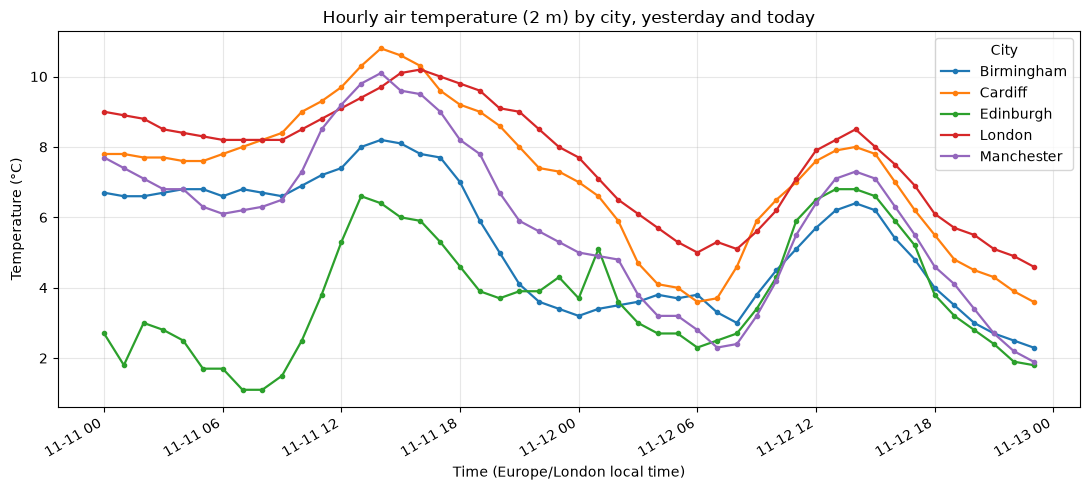

In [16]:
plot_df = latest.assign(time=pd.to_datetime(latest["time"]))
fig, ax = plt.subplots(figsize=(11, 5))
for city, g in plot_df.groupby("city"):
    ax.plot(g["time"], g["temperature_2m"], marker=".", linewidth=1.6, label=city)
ax.set_title("Hourly air temperature (2 m) by city, yesterday and today")
ax.set_xlabel("Time (Europe/London local time)")
ax.set_ylabel("Temperature (°C)")
ax.grid(alpha=0.3)
ax.legend(title="City")
fig.autofmt_xdate()
fig.tight_layout()
(ROOT / "docs" / "figures").mkdir(parents=True, exist_ok=True)
fig.savefig(ROOT / "docs" / "figures" / "temperature_by_city.png", dpi=120)
plt.show()

## 6. Findings

The numbers below are from my run on 12 November 2026: two runs of `extract.py` a few seconds apart,
10 raw files, 480 rows. When you re-run the notebook the counts change with the files in `data/raw/`,
but the patterns stay the same.

1. **`time` is loaded as text, not a datetime, and it has no offset.** The dtype is `str`, with values
   like `'2026-11-11T00:00'`. It is Europe/London local time, which I know only from `timezone` in the
   payload (`GMT`, `utc_offset_seconds = 0` today). It must be converted with `pd.to_datetime` before
   sorting or filtering by date. In summer the same text means one hour earlier in UTC, and on the night
   the clocks go back in October one local hour happens twice, so a UTC column is needed before
   `(city, time)` can be trusted as a key.

2. **Every hour appears once per extract run, so there are duplicates.** 480 rows hold only 240 distinct
   `(city, time)` pairs, because each response covers the same 48-hour window (yesterday 00:00 to today
   23:00). This time the two copies matched in all 240 pairs, but forecast values can change between
   runs. So the transform in Task 1.5 must keep the **latest** copy, and loading must replace rows rather
   than append them.

3. **The window mixes past and forecast hours, and no column says which.** With `past_days=1` and
   `forecast_days=1`, the first 24 hours are yesterday and the last 24 are today, including hours that
   have not happened yet. A column named `observed_at` (Task 1.5) is slightly misleading for the future
   hours. Later weeks should add a flag, or compare the value against the run time.

4. **No nulls today, and the ranges are realistic for a UK November.** All 11 columns have 0 nulls.
   Temperature ranges from 1.1 °C (Edinburgh) to 10.8 °C (Cardiff), humidity from 50 to 97 %, wind up to
   19.1 km/h and rain up to 1.6 mm in an hour (Birmingham). Feels-like temperature is on average about
   3 °C below air temperature (mean 2.8 vs 6.0 °C) and drops to −2.2 °C in Edinburgh, which matters for
   outdoor crews. The data dictionary still marks the weather values as nullable, because Open-Meteo
   returns `null` when a model has no value.

5. **`weather_code` is a number that needs a lookup table.** Only 8 distinct WMO codes appear:
   0–3 (clear to overcast), 51/53/55 (light to dense drizzle) and 61 (slight rain). "Clear sky" is the
   most common. On their own the codes mean nothing to a planner, so the pipeline needs a code →
   description (and later code → risk) lookup.

6. **The returned coordinates are not the ones I requested.** Open-Meteo snaps each request to its model
   grid cell. London was requested at 51.50853, −0.12574 and returned as 51.51147, −0.13078, and Cardiff's
   longitude is off by 0.0128°. So the `latitude`/`longitude` columns describe the grid cell, not the city
   centre, and should never be used as a join key. The city name is the key.